# Flood MPI: real corner (1 m) vs. PhaseTrace — wall reflectivity

Which diffuse reflectivity of the walls makes the simulated flood behave like the real one?

- **Real:** the flood clouds of `MPI_sweep_real.ipynb` (`MPI_1m_WW`, first frame, SOR), exported by its
  last cell to `Results/mpi_sweep_real/flood_export_MPI_1m_WW.pkl`.
- **Simulation:** one PhaseTrace scene per corner that reproduces the real geometry — the two walls of
  the 33x33 triangulation (angle, rotation, fold offset) scaled along the rays to the tape-measured
  fold distance of 1.03 m, each wall 0.69 m long (fold → edge), top edge measured in the flood depth
  image, bottom below the field of view. Camera, film and flood light as the `Flood_y` scenes of
  `Structured_Light_y.py` (laser 110° at the camera, 0.5 W, 12 ms), but at **100 MHz** like the real
  camera (the generator used 10 MHz).
- **Comparison without ground truth:** every flood cloud — real or simulated — gets its own two walls
  (RANSAC on the points farther than the margin from the fold). The **fold dip** (mean depth error
  within ±5 cm of the fold against these walls) is the multipath signature; it does not depend on the
  unknown range offset of the real flood (VCSEL 4 has no calibration) nor on the scale of any
  calibration. The apparent inner angle of the own walls is shown as a second, weaker indicator (the
  real reference angle is only known to ±2–3°: 10x10 vs. 33x33 triangulation).

In [1]:
import os, pickle, re, subprocess, time, warnings
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore", category=RuntimeWarning)

EXPORT      = Path.cwd().parent / "Results" / "mpi_sweep_real" / "flood_export_MPI_1m_WW.pkl"
PBRT_ROOT   = Path("/home/julian/Documents/projects/PBRT")
PHASETRACE  = PBRT_ROOT / "camerasimulationgpu/camerasimulationgpu/build/phasetrace"
SCENE_ROOT  = PBRT_ROOT / "tof_camerasimulation/test_scenes/Final_Scenes/MPI_real1m"
OUT_ROOT    = PBRT_ROOT / "camerasimulationgpu/camerasimulationgpu/output/Flood_real1m"

REFL_GRID   = (0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6, 0.8, 0.95)
SPP         = 1024          # see the convergence test below
F_MOD       = 100           # [MHz] as the real camera
WALL_LENGTH = 0.69          # [m] fold → outer edge
Y_BOTTOM    = 1.0           # [m] bottom edge (camera y, down) — below the field of view
FOLD_MARGIN = 0.15          # [m] along the wall, as in MPI_sweep_real
RENDER      = True          # False → only evaluate existing renders

with open(EXPORT, "rb") as f:
    EX = pickle.load(f)
ANGLES, TAPE = EX["angles"], EX["tape"]
print(f"real: {EX['meas_root']}  ({EX['frame_mode']} frame, SOR {EX['sor']}), angles {ANGLES}, tape {TAPE} m")

real: /home/julian/Documents/Calibrations/MPI_Messung_07.10/MPI_1m_WW  (first frame, SOR _sor6-0.40), angles [30, 45, 60, 90], tape 1.03 m


## Geometry helpers (as in `MPI_sweep_real.ipynb`)

In [2]:
_rng = np.random.default_rng(1)


def fit_plane(P):
    c = P.mean(axis=0)
    n = np.linalg.svd(P - c, full_matrices=False)[2][2]
    d = -n @ c
    return (n, d) if d > 0 else (-n, -d)


def ransac_plane(P, thr=0.015, iters=300):
    best = None
    for _ in range(iters):
        p = P[_rng.choice(len(P), 3, replace=False)]
        n = np.cross(p[1] - p[0], p[2] - p[0])
        if np.linalg.norm(n) < 1e-12:
            continue
        n /= np.linalg.norm(n)
        inl = np.abs((P - p[0]) @ n) < thr
        if best is None or inl.sum() > best.sum():
            best = inl
    for _ in range(2):
        n, d = fit_plane(P[best])
        best = np.abs(P @ n + d) < thr
    return n, d


def ray_range_to_corner(P, walls):
    dh = P / np.linalg.norm(P, axis=1, keepdims=True)
    t = np.stack([-d / (dh @ np.asarray(n)) for n, d in walls], axis=1)
    t[t <= 0] = np.inf
    return t.min(axis=1)


def corner_frame(walls):
    (n1, d1), (n2, d2) = [(np.asarray(n, float), float(d)) for n, d in walls]
    ey = np.cross(n1, n2); ey /= np.linalg.norm(ey)
    if ey[1] < 0:
        ey = -ey
    O = np.linalg.solve(np.array([n1, n2, ey]), np.array([-d1, -d2, 0.0]))
    ez = O - (O @ ey) * ey; ez /= np.linalg.norm(ez)
    ex = np.cross(ey, ez)
    if ex[0] < 0:
        ex = -ex
    R = np.stack([ex, ey, ez]); dist = float(np.linalg.norm(O)); sh = np.array([0.0, 0.0, dist])
    lines = []
    for n, d in ((n1, d1), (n2, d2)):
        nc = R @ n
        lines.append((nc[0], nc[2], d + n @ O - nc @ sh))
    (a1, b1, c1), (a2, b2, c2) = lines
    xf, zf = np.linalg.solve([[a1, b1], [a2, b2]], [-c1, -c2])
    ends = []
    for a, b, _ in lines:
        t = np.array([b, -a]) / np.hypot(a, b)
        t = t if t[1] < 0 else -t
        ends.append((xf + WALL_LENGTH * t[0], zf + WALL_LENGTH * t[1]))
    c = np.array([ends[0], [xf, zf], ends[1]]); c = c[np.argsort(c[:, 0])]
    v = [(q - c[1]) / np.linalg.norm(q - c[1]) for q in c[[0, 2]]]
    inner = float(np.degrees(np.arccos(np.clip(v[0] @ v[1], -1, 1))))
    return dict(to=lambda P: (np.asarray(P) - O) @ R.T + sh, R=R, O=O, ey=ey, ez=ez, dist=dist,
                corner=c, walls=[(n1, d1), (n2, d2)], inner=inner,
                mx=FOLD_MARGIN * np.sin(np.radians(inner / 2)))


def z_gt(x, c):
    return np.interp(x, c[:, 0], c[:, 1], left=np.nan, right=np.nan)

## Real geometry → simulation scenes

Walls of the 33x33 triangulation, scaled along the rays to the tape distance (a triangulation scale
error does not change the angles). The top edge of the walls is the depth jump above the fold in the
real flood depth image (per column, median per wall).

In [3]:
SCENE_GEOM = {}
for a in ANGLES:
    w = EX["walls_33x33"][a]
    s = TAPE / corner_frame(w)["dist"]
    walls = [(np.asarray(n), s * d) for n, d in w]
    F = corner_frame(walls)
    Pm, uf = EX["flood"][a], EX["u_fold"][a]
    tops = {-1: [], 1: []}
    for u in range(max(5, uf - 150), min(Pm.shape[1] - 5, uf + 150), 4):
        if abs(u - uf) < 8:
            continue
        z, v = Pm[:, u, 2], 200
        if not np.isfinite(z[v]):
            continue
        while v > 1 and np.isfinite(z[v - 1]) and abs(z[v - 1] - z[v]) < 0.04:
            v -= 1
        if v <= 1:
            continue
        r = Pm[v, u] / np.linalg.norm(Pm[v, u])
        tops[int(np.sign(u - uf))].append((r * ray_range_to_corner(r[None], walls)[0])[1])
    SCENE_GEOM[a] = dict(walls=walls, frame=F, y_top=[float(np.median(tops[-1])), float(np.median(tops[1]))])
    print(f"{a}°: scale {s:.4f}, fold at {F['dist']:.3f} m, inner {F['inner']:.1f}°, "
          f"fold line tilt {np.degrees(np.arcsin(-F['ey'][2])):+.1f}°, top edge y = "
          f"{SCENE_GEOM[a]['y_top'][0]:+.3f} / {SCENE_GEOM[a]['y_top'][1]:+.3f} m (camera, down +)")


def scene_text(stem, a, refl, spp=SPP, fmod=F_MOD):
    g = SCENE_GEOM[a]; F = g["frame"]
    at = lambda y: F["O"] + (y - F["O"][1]) / F["ey"][1] * F["ey"]        # fold point at camera height y
    verts, idx = [], []
    for k, (n, _) in enumerate(F["walls"]):
        t = np.cross(n, F["ey"]); t /= np.linalg.norm(t)
        t = -t if t @ F["ez"] > 0 else t
        ft, fb = at(g["y_top"][k]), at(Y_BOTTOM)
        b = len(verts)
        verts += [ft, fb, fb + WALL_LENGTH * t, ft + WALL_LENGTH * t]
        idx += [b, b + 1, b + 2, b, b + 2, b + 3]
    V = np.array(verts) * np.array([1, -1, 1])                              # camera y down → scene y up
    pts = "\n".join(f"      {v[0]:.6f} {v[1]:.6f} {v[2]:.6f}" for v in V)
    return f'''LookAt 0 0 0
    0 0 1
    0 1 0
Camera "perspective"
  "float fovX" [ 67 ]
  "float fovY" [ 51 ]
  "float shutterclose" [ 0.012 ]
  "float shutteropen" [ 0.0 ]

Film "tof"
    "string filename" [ "output/{stem}.pcd" ]
    "integer yresolution" [ 480 ]
    "integer xresolution" [ 640 ]
    "float pixelSize" [ 10. ]
    "bool modelNoise" [ true ]
    "float modulationFrequency" [ {fmod:g}. ]
    "string correlationType" [ "cos" ]
    "float wavelength" [ 940. ]
    "float demodulationContrast" [ .98 ]
    "float dutyCycle" [ .5 ]
    "float quantumEfficiency" [ .34 ]
    "float maxElectrons" [ 150000.0 ]
    "float minAmplitude" [ 0.003 ]

Sampler "halton"
    "integer pixelsamples" [ {spp} ]


WorldBegin

LightSource "laser"
    "float coneangle" [110]
    "float conedeltaangle" [0.01]
    "point3 from" [ 0.001 0.0 0.0 ]
    "point3 to" [ 0 0 1.000000 ]
    "float power" [ 0.5 ]
    "integer wavelength" [ 940 ]

Material "diffuse" "rgb reflectance" [ {refl:g} {refl:g} {refl:g} ]
Shape "trianglemesh"
  "integer indices" [ {" ".join(map(str, idx))} ]
  "point3 P" [
{pts}
  ]
'''


def render(a, refl, spp=SPP, fmod=F_MOD, tag=""):
    # Write the scene and render it unless the output exists; returns the PCD path.
    stem = f"ToF_MPI_{a}deg_Flood{tag}"
    sdir, wdir = SCENE_ROOT / f"refl_{refl:.2f}", OUT_ROOT / f"refl_{refl:.2f}"
    sdir.mkdir(parents=True, exist_ok=True); (wdir / "output").mkdir(parents=True, exist_ok=True)
    scene, pcd = sdir / f"{stem}.pbrt", wdir / "output" / f"{stem}.pcd"
    scene.write_text(scene_text(stem, a, refl, spp, fmod))
    if RENDER and not pcd.exists():
        subprocess.run([str(PHASETRACE), "--gpu", str(scene)], cwd=wdir, check=True,
                       stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    return pcd

30°: scale 0.8736, fold at 1.030 m, inner 24.3°, fold line tilt +4.2°, top edge y = -0.286 / -0.285 m (camera, down +)
45°: scale 0.8814, fold at 1.030 m, inner 38.2°, fold line tilt +4.1°, top edge y = -0.289 / -0.286 m (camera, down +)
60°: scale 0.8835, fold at 1.030 m, inner 52.2°, fold line tilt +4.0°, top edge y = -0.291 / -0.286 m (camera, down +)
90°: scale 0.8788, fold at 1.030 m, inner 80.2°, fold line tilt +3.8°, top edge y = -0.291 / -0.285 m (camera, down +)


## Metrics

`own_walls` fits two walls to a flood cloud (inside the real region of interest, farther than the
margin from the fold — the split uses the scene frame) and returns, relative to these walls, the fold
dip, the median profile across the fold and the apparent inner angle.

In [4]:
def load_sim(pcd):
    a = np.loadtxt(pcd, skiprows=11, dtype=np.float32)[:, :3].astype(float) / 1000.0
    a[:, 1] *= -1                                       # scene y up → camera y down
    a[~(np.abs(a).sum(axis=1) > 0)] = np.nan            # invalid pixels are (0, 0, 0)
    return a


def own_walls(P, a):
    F = SCENE_GEOM[a]["frame"]; (x0, x1), (y0, y1) = EX["roi"][a]
    P = P[np.isfinite(P).all(axis=1) & (P[:, 2] > 0.1) & (P[:, 2] < 1.45)]
    rh = P / np.linalg.norm(P, axis=1, keepdims=True)
    Q = F["to"](rh * ray_range_to_corner(P, F["walls"])[:, None])
    keep = (Q[:, 0] >= x0) & (Q[:, 0] <= x1) & (Q[:, 1] >= y0) & (Q[:, 1] <= y1)
    P, Q = P[keep], Q[keep]
    xr = Q[:, 0] - F["corner"][1, 0]
    walls = [ransac_plane(P[side][::3]) for side in (xr < -F["mx"], xr > F["mx"])]
    G = corner_frame(walls)
    Pc = G["to"](P); x2 = Pc[:, 0] - G["corner"][1, 0]
    dz = Pc[:, 2] - z_gt(Pc[:, 0], G["corner"])
    edges = np.arange(-0.6, 0.6001, 0.01); idx = np.digitize(x2, edges) - 1
    med = np.array([np.nanmedian(dz[idx == k]) if (idx == k).sum() > 20 else np.nan for k in range(len(edges) - 1)])
    return dict(fold=float(np.nanmean(dz[np.abs(x2) < 0.05])), inner=G["inner"], x=edges[:-1] + 0.005, med=med)


REAL = {a: own_walls(EX["flood"][a].reshape(-1, 3), a) for a in ANGLES}
for a in ANGLES:
    print(f"real {a}°: fold dip {REAL[a]['fold'] * 1e3:+6.1f} mm, own inner angle {REAL[a]['inner']:5.1f}° "
          f"(33x33 triangulation {SCENE_GEOM[a]['frame']['inner']:.1f}°)")

real 30°: fold dip  -81.0 mm, own inner angle  25.0° (33x33 triangulation 24.3°)
real 45°: fold dip  -84.4 mm, own inner angle  37.5° (33x33 triangulation 38.2°)
real 60°: fold dip  -64.0 mm, own inner angle  52.3° (33x33 triangulation 52.2°)
real 90°: fold dip  -31.3 mm, own inner angle  83.5° (33x33 triangulation 80.2°)


## Sample count

The 30° corner (strongest interreflection) at reflectivity 0.8 with 256 / 512 / 1024 samples per
pixel: fold dip and median profile against 1024 spp. A render takes ≈ 3 / 5 / 10 s on the RTX 2060
SUPER, so 1024 spp costs nothing here.

In [5]:
conv = {spp: own_walls(load_sim(render(30, 0.8, spp=spp, tag=f"_spp{spp}")), 30) for spp in (256, 512, 1024)}
for spp in (256, 512):
    m = np.isfinite(conv[spp]["med"]) & np.isfinite(conv[1024]["med"])
    rms = np.sqrt(np.mean((conv[spp]["med"][m] - conv[1024]["med"][m]) ** 2))
    print(f"{spp:5d} spp vs 1024: profile RMS {rms * 1e3:.2f} mm, fold dip {conv[spp]['fold'] * 1e3:+.1f} "
          f"vs {conv[1024]['fold'] * 1e3:+.1f} mm")

  256 spp vs 1024: profile RMS 5.14 mm, fold dip -168.3 vs -164.1 mm
  512 spp vs 1024: profile RMS 1.12 mm, fold dip -163.2 vs -164.1 mm


## Reflectivity sweep

In [6]:
t0 = time.time()
SIM = {r: {a: own_walls(load_sim(render(a, r)), a) for a in ANGLES} for r in REFL_GRID}
print(f"{len(REFL_GRID) * len(ANGLES)} scenes ready in {time.time() - t0:.0f} s")

rows = []
print(f"{'r':>5s}  fold dip [mm] per angle" + " " * 20 + "RMS vs real   apparent angle − scene angle [°]")
for r in REFL_GRID:
    e_fold = np.sqrt(np.mean([(SIM[r][a]["fold"] - REAL[a]["fold"]) ** 2 for a in ANGLES]))
    rows.append((r, e_fold))
    print(f"{r:5.2f}  " + "  ".join(f"{a}° {SIM[r][a]['fold'] * 1e3:+6.0f}" for a in ANGLES)
          + f"   {e_fold * 1e3:6.1f} mm   " + "  ".join(f"{SIM[r][a]['inner'] - SCENE_GEOM[a]['frame']['inner']:+5.1f}" for a in ANGLES))
print("real   " + "  ".join(f"{a}° {REAL[a]['fold'] * 1e3:+6.0f}" for a in ANGLES) + " " * 19
      + "  ".join(f"{REAL[a]['inner'] - SCENE_GEOM[a]['frame']['inner']:+5.1f}" for a in ANGLES))
R_BEST = min(rows, key=lambda t: t[1])[0]
print(f"\nbest reflectivity (fold dip): r = {R_BEST:.2f}")

44 scenes ready in 19 s
    r  fold dip [mm] per angle                    RMS vs real   apparent angle − scene angle [°]
 0.20  30°    -23  45°    -38  60°    -38  90°    -28     39.2 mm    -0.3   -1.7   -2.6   -3.7
 0.25  30°    -30  45°    -49  60°    -48  90°    -34     32.1 mm    -0.4   -2.2   -3.3   -4.5
 0.30  30°    -37  45°    -59  60°    -58  90°    -41     25.9 mm    -0.5   -2.7   -3.9   -5.3
 0.35  30°    -45  45°    -70  60°    -68  90°    -48     21.1 mm    -0.7   -3.2   -4.6   -6.1
 0.40  30°    -53  45°    -83  60°    -79  90°    -54     19.7 mm    -0.8   -3.7   -5.4   -7.0
 0.45  30°    -62  45°    -97  60°    -91  90°    -61     23.1 mm    -1.0   -4.4   -6.1   -7.8
 0.50  30°    -71  45°   -112  60°   -104  90°    -68     30.9 mm    -1.2   -5.1   -6.9   -8.7
 0.55  30°    -81  45°   -130  60°   -119  90°    -75     42.0 mm    -1.4   -5.8   -7.9   -9.5
 0.60  30°    -93  45°   -150  60°   -131  90°    -83     53.8 mm    -1.6   -6.6   -8.6  -10.4
 0.80  30°   -158  45°  

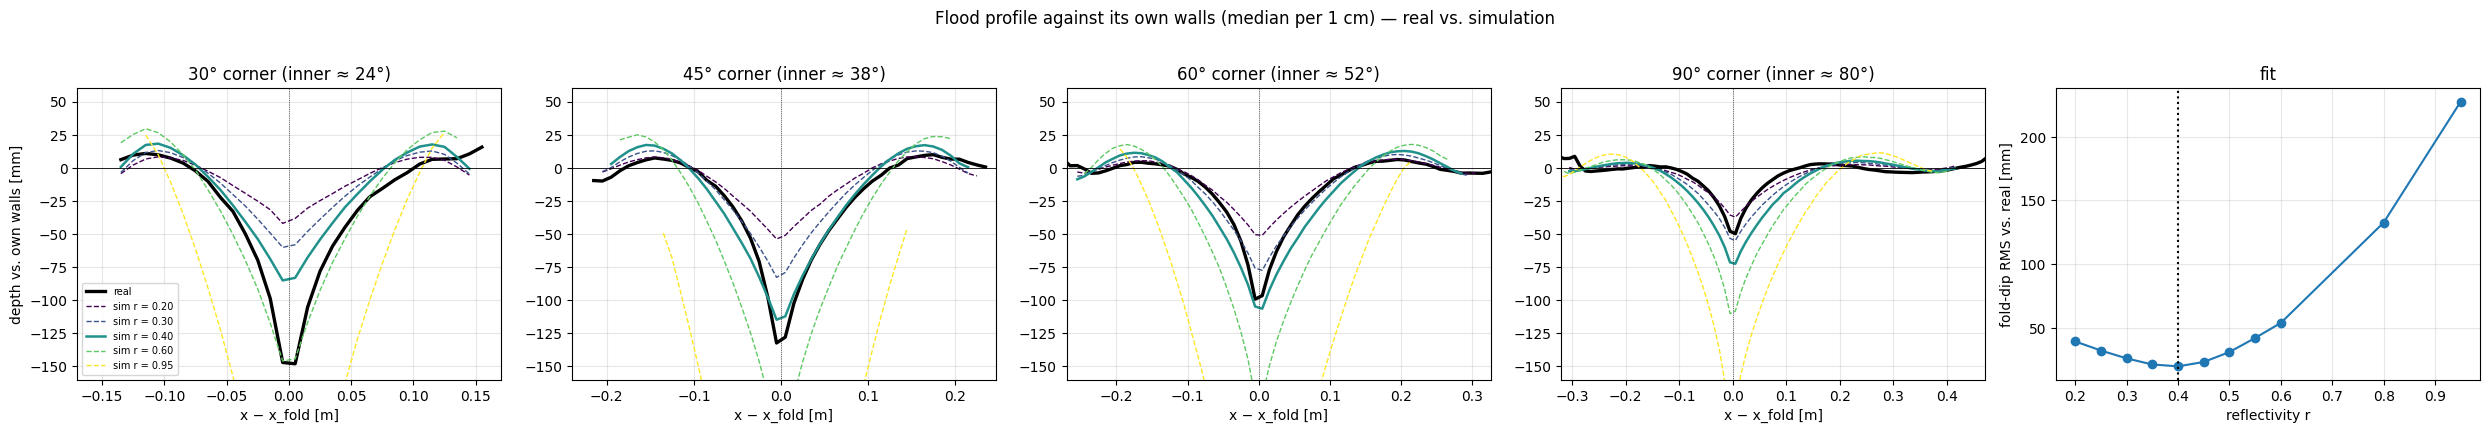

In [7]:
fig, axs = plt.subplots(1, len(ANGLES) + 1, figsize=(5 * (len(ANGLES) + 1), 4.2))
show = [r for r in REFL_GRID if r in (0.2, 0.3, R_BEST, 0.6, 0.95)]
cols = plt.cm.viridis(np.linspace(0, 1, len(show)))
for ax, a in zip(axs, ANGLES):
    ax.plot(REAL[a]["x"], REAL[a]["med"] * 1e3, "k-", lw=2.4, label="real")
    for r, c in zip(show, cols):
        ax.plot(SIM[r][a]["x"], SIM[r][a]["med"] * 1e3, color=c, lw=1.8 if r == R_BEST else 1.0,
                ls="-" if r == R_BEST else "--", label=f"sim r = {r:.2f}")
    ax.axhline(0, color="k", lw=0.6); ax.axvline(0, color="k", lw=0.5, ls=":")
    ax.set_xlim(EX["roi"][a][0][0] - 0.02, EX["roi"][a][0][1] + 0.02); ax.set_ylim(-160, 60)
    ax.set_title(f"{a}° corner (inner ≈ {SCENE_GEOM[a]['frame']['inner']:.0f}°)"); ax.grid(alpha=0.3)
    ax.set_xlabel("x − x_fold [m]")
axs[0].set_ylabel("depth vs. own walls [mm]"); axs[0].legend(fontsize=7)
ax = axs[-1]
ax.plot([t[0] for t in rows], [t[1] * 1e3 for t in rows], "o-")
ax.axvline(R_BEST, color="k", ls=":")
ax.set_xlabel("reflectivity r"); ax.set_ylabel("fold-dip RMS vs. real [mm]"); ax.grid(alpha=0.3)
ax.set_title("fit")
fig.suptitle("Flood profile against its own walls (median per 1 cm) — real vs. simulation", y=1.02)
fig.tight_layout()
plt.show()

## Modulation frequency: 10 MHz (old generator) vs. 100 MHz

In [8]:
S10 = {a: own_walls(load_sim(render(a, R_BEST, fmod=10, tag="_10MHz")), a) for a in ANGLES}
for a in ANGLES:
    print(f"{a}°: fold dip 100 MHz {SIM[R_BEST][a]['fold'] * 1e3:+6.1f} mm, 10 MHz {S10[a]['fold'] * 1e3:+6.1f} mm, "
          f"real {REAL[a]['fold'] * 1e3:+6.1f} mm")

30°: fold dip 100 MHz  -53.1 mm, 10 MHz  -88.8 mm, real  -81.0 mm
45°: fold dip 100 MHz  -82.5 mm, 10 MHz -123.0 mm, real  -84.4 mm
60°: fold dip 100 MHz  -79.3 mm, 10 MHz -109.1 mm, real  -64.0 mm
90°: fold dip 100 MHz  -54.4 mm, 10 MHz  -93.3 mm, real  -31.3 mm


## Notes

- Fold dip is measured against each cloud's own walls, so neither the unknown range offset of the
  real flood (VCSEL 4, no calibration) nor the scale of a calibration enters. The apparent inner angle
  is only a weak indicator: the real reference angle comes from the 33x33 triangulation, and 10x10
  and 33x33 disagree by up to 5° at 90°.
- A single Lambertian reflectivity cannot reproduce every angle: real, the fold dip falls from 30° to
  90° much more than simulated, and the real walls are hardly bent (apparent angle ≈ triangulated),
  while the simulated ones bend with growing r. Candidates: a non-Lambertian target material, the real
  position of VCSEL 4 (the simulation puts the flood at the lens), the floor/background next to the
  target, and the real wall height / bottom edge.
- Modulation frequency: at the best reflectivity the 10 MHz render (old generator) deepens the fold dip
  by ≈ 30–40 mm at every angle compared with 100 MHz; at 100 MHz the long interreflection paths wrap
  (unambiguity 1.5 m) and partly cancel. The simulation therefore has to run at the real 100 MHz.
- Sample count: 512 spp stays within ≈ 1 mm of 1024 spp (fold dip and profile); 1024 is used because a
  render only takes ≈ 10 s.
- Renders: `camerasimulationgpu/output/Flood_real1m/refl_<r>/output/`, scenes:
  `test_scenes/Final_Scenes/MPI_real1m/refl_<r>/`.